# HDT 8: Redes Neuronales

**Ciencia de Datos, Sección A** · Asignada: jueves 15 de octubre · **Entrega: martes 27 de octubre, 23:59**

**Nombre:** _Juan David Contreras_

Completar las celdas marcadas con `# ¿Qué va aquí?`. Cada ejercicio incluye una verificación comentada: descomentar para comprobar el resultado. Antes de entregar: **Kernel → Restart & Run All** (un notebook que no corre de arriba a abajo pierde 0.5 pts).

La entrega es el martes del repaso (el 20 es feriado): no la dejen para el final, el Parcial II es el jueves 29.

AI: resolver sin AI. Si se usó para entender un concepto, anotarlo en la bitácora del final (no penaliza).

## Setup

Dependencias: `pip install numpy pandas matplotlib scikit-learn`. Todo es determinista (semillas fijas y splits fijos): las verificaciones son exactas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

def frontera(modelo, X, y, ax, titulo):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 150),
                         np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 150))
    Z = modelo.predict(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=[AZUL, ROJO], alpha=0.2)
    ax.scatter(X[:, 0], X[:, 1], c=np.where(y == 1, ROJO, AZUL), s=12)
    ax.set_title(titulo, fontsize=10)

## Los datos

Dos problemas donde la forma importa:

**La alarma** (parte A): un sensor dispara la alarma cuando **exactamente una** de dos señales está encendida (la diagonal de la sesión 22, con otros 240 puntos). **Los anillos** (parte B): un punto adentro de un anillo, como el ejercicio 2 de clase, con otros números.

In [2]:
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(15)
esquinas = rng.integers(0, 2, size=(240, 2))
X_alarma = esquinas + rng.normal(0, 0.15, (240, 2))
y_alarma = (esquinas[:, 0] != esquinas[:, 1]).astype(int)

X_ani, y_ani = make_circles(n_samples=500, noise=0.12, factor=0.45, random_state=8)
Xa_train, Xa_test, ya_train, ya_test = train_test_split(X_ani, y_ani, test_size=0.3, random_state=42)

print("alarma:", len(X_alarma), "puntos | anillos:", len(X_ani), "puntos")

alarma: 240 puntos | anillos: 500 puntos


## Parte A · La recta falla, la red a mano no (0.7 pt)

### Ejercicio 1 (0.20): la recta contra la diagonal

Entrenar una `LogisticRegression` sobre la alarma y reportar sus aciertos. Graficar los puntos (ROJO = alarma, AZUL = no) con `eje_limpio`. En un comentario: ¿por qué este número y no algo mejor?

aciertos de la recta: 0.54


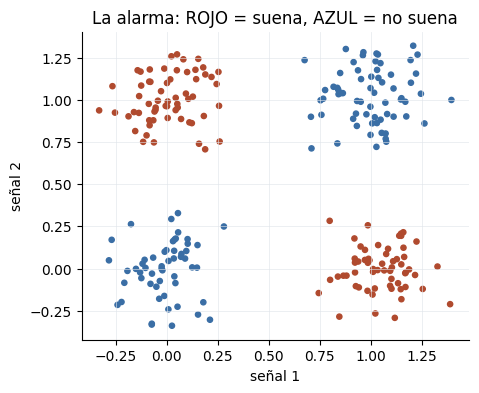

In [3]:
from sklearn.linear_model import LogisticRegression

recta = LogisticRegression().fit(X_alarma, y_alarma)
aciertos_recta = recta.score(X_alarma, y_alarma)
print("aciertos de la recta:", round(aciertos_recta, 2))

# graficar los puntos
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X_alarma[:, 0], X_alarma[:, 1], c=np.where(y_alarma == 1, ROJO, AZUL), s=14)
ax.set_xlabel("señal 1"); ax.set_ylabel("señal 2")
ax.set_title("La alarma: ROJO = suena, AZUL = no suena")
eje_limpio(ax)
plt.show()

# Respuesta: 0.54, apenas por encima de tirar una moneda. Los rojos están en las
# esquinas (0,1) y (1,0) y los azules en (0,0) y (1,1): ningún recta puede dejar
# los rojos de un lado y los azules del otro, porque cada lado de la recta
# siempre mezcla ambas clases. Es el techo geométrico de un modelo lineal.

# Verificación (descomentar):
assert round(aciertos_recta, 2) == 0.54

### Ejercicio 2 (0.30): la red a mano, verificada

Completar `red_a_mano` con la receta de clase: neurona 1 con pesos $(2, 2)$ y sesgo $-1$; neurona 2 con pesos $(2, 2)$ y sesgo $-3$; ambas con ReLU; salida $= h_1 - 3 h_2$. Armar la tabla de las cuatro esquinas e imprimirla.

In [4]:
def relu(z):
    return np.maximum(0, z)

def red_a_mano(x1, x2):
    h1 = relu(2 * x1 + 2 * x2 - 1)
    h2 = relu(2 * x1 + 2 * x2 - 3)
    return h1 - 3 * h2

filas = []
for x1, x2 in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    h1 = relu(2 * x1 + 2 * x2 - 1)
    h2 = relu(2 * x1 + 2 * x2 - 3)
    filas.append({"x1": x1, "x2": x2, "h1": h1, "h2": h2, "salida": h1 - 3 * h2})
print(pd.DataFrame(filas))

# Verificación (descomentar):
assert red_a_mano(0, 1) == 1 and red_a_mano(1, 0) == 1
assert red_a_mano(0, 0) == 0 and red_a_mano(1, 1) == 0

   x1  x2  h1  h2  salida
0   0   0   0   0       0
1   0   1   1   0       1
2   1   0   1   0       1
3   1   1   3   1       0


### Ejercicio 3 (0.20): la misma red sobre los 240 puntos

Aplicar `red_a_mano` a todos los puntos de la alarma (decidir sí cuando la salida pasa de 0.5) y reportar los aciertos. Comparar contra la recta del ejercicio 1 en un comentario.

In [6]:
salidas = red_a_mano(X_alarma[:, 0], X_alarma[:, 1])
pred_mano = (salidas > 0.5).astype(int)
aciertos_mano = (pred_mano == y_alarma).mean()
print("aciertos de la red a mano:", round(aciertos_mano, 2))

# Respuesta: la red a mano acierta 0.89 contra 0.54 de la recta. La capa oculta
# con ReLU permite "doblar" el plano: h1 se enciende con al menos una señal y h2
# solo con las dos, y restar 3*h2 apaga la esquina (1,1). El 11% que falla son
# puntos cuyo ruido los empuja del otro lado de los umbrales (0.5 y 1.5 de
# x1+x2); la recta no tenía forma de resolver el problema, la red sí.

# Verificación (descomentar):
assert round(aciertos_mano, 2) == 0.89

aciertos de la red a mano: 0.89


## Parte B · La red que aprende (0.7 pt)

Los anillos: un círculo adentro de otro. La pregunta de la clase: ¿cuántos quiebres pide esta frontera?

### Ejercicio 4 (0.25): ¿cuántas neuronas pide un anillo?

Para [1, 2, 4, 8, 16, 64] neuronas de en medio: entrenar `MLPClassifier` (`activation="relu"`, `max_iter=3000`, `random_state=0`) sobre el train de los anillos y guardar train y test en una tabla. ¿Dónde deja de mejorar?

In [7]:
from sklearn.neural_network import MLPClassifier

filas = []
for h in [1, 2, 4, 8, 16, 64]:
    mlp = MLPClassifier(hidden_layer_sizes=(h,), activation="relu",
                        max_iter=3000, random_state=0).fit(Xa_train, ya_train)
    filas.append({"neuronas": h,
                  "train": round(mlp.score(Xa_train, ya_train), 2),
                  "test": round(mlp.score(Xa_test, ya_test), 2)})
tabla_h = pd.DataFrame(filas)
print(tabla_h)

# ¿Dónde deja de mejorar? Con 1-2 neuronas la frontera es una recta (o casi) y no
# separa el anillo (test 0.45 y 0.58). Con 4 salta a 0.95 y con 8 llega a 0.99;
# de 8 en adelante el test queda clavado en 0.99: más neuronas no aportan nada.

# Verificación (descomentar):
assert tabla_h["test"].tolist() == [0.45, 0.58, 0.95, 0.99, 0.99, 0.99]

   neuronas  train  test
0         1   0.52  0.45
1         2   0.58  0.58
2         4   0.98  0.95
3         8   1.00  0.99
4        16   0.99  0.99
5        64   0.99  0.99


### Ejercicio 5 (0.25): las fronteras, dibujadas

Tres paneles con `frontera(...)`: redes de 1, 4 y 8 neuronas sobre el test de los anillos, con los aciertos de test en cada título.

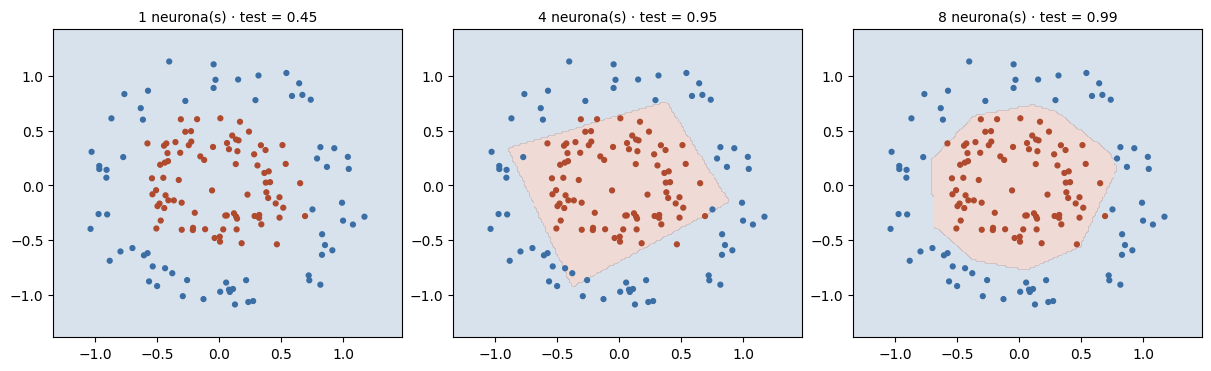

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
for ax, h in zip(axes, [1, 4, 8]):
    mlp = MLPClassifier(hidden_layer_sizes=(h,), activation="relu",
                        max_iter=3000, random_state=0).fit(Xa_train, ya_train)
    frontera(mlp, Xa_test, ya_test, ax,
             f"{h} neurona(s) · test = {mlp.score(Xa_test, ya_test):.2f}")
plt.show()

# 1 neurona = una recta; 4 = un cuadrilátero que encierra el círculo interno;
# 8 = un polígono más fino que se ajusta casi a la forma circular.

# Verificación (descomentar):
assert len(axes) == 3

### Ejercicio 6 (0.20): el tamaño del paso, otra vez

Entrenar la red de 8 neuronas con `solver="sgd"` y `learning_rate_init` en [0.001, 0.1, 8.0] (`max_iter=400`), graficando la curva de error (`loss_curve_`) de cada una. Guardar los aciertos de test en `tests_paso`. En un comentario: ¿qué historia cuenta cada curva?

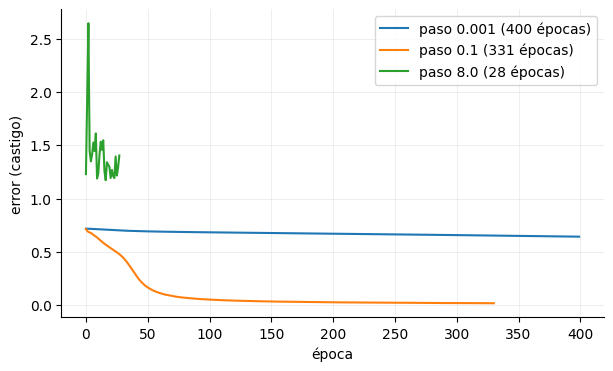

{0.001: 0.667, 0.1: 0.973, 8.0: 0.553}


In [9]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

tests_paso = {}
fig, ax = plt.subplots(figsize=(7, 4))
for lr in [0.001, 0.1, 8.0]:
    mlp = MLPClassifier(hidden_layer_sizes=(8,), activation="relu", solver="sgd",
                        learning_rate_init=lr, max_iter=400,
                        random_state=0).fit(Xa_train, ya_train)
    ax.plot(mlp.loss_curve_, label=f"paso {lr} ({len(mlp.loss_curve_)} épocas)")
    tests_paso[lr] = mlp.score(Xa_test, ya_test)
ax.set_xlabel("época"); ax.set_ylabel("error (castigo)")
ax.legend(); eje_limpio(ax)
plt.show()
print({k: round(v, 3) for k, v in tests_paso.items()})

# Respuesta:
# - paso 0.001: demasiado chico. El error baja muy lento (de ~0.72 a ~0.64 en 400
#   épocas), no llega a ningún lado y el test queda en 0.67.
# - paso 0.1: el adecuado. El error cae de ~0.71 a ~0.02 y el test llega a 0.97.
# - paso 8.0: demasiado grande. Se pasa del valle en cada salto, el error sube
#   (de ~1.23 a ~1.40) y el test es 0.55, casi azar.

# Verificación (descomentar):
assert round(tests_paso[0.1], 2) == 0.97
assert tests_paso[8.0] < 0.6

## Parte C · La culpa, a mano (0.4 pt)

Backpropagation en miniatura: UNA neurona, UN peso, y la pregunta de la sesión: ¿cuánto ayudó este peso al error? Sin derivadas: se le sube un poquito y se mira qué pasa.

### Ejercicio 7 (0.40): mover un peso en contra de su culpa

Una neurona sola decide si un cliente con `x` meses de atraso cae en mora: $p = \text{sigmoide}(w \cdot x - 2.5)$. Datos: x = [1, 2, 3, 4], y = [0, 0, 1, 1]. La función `castigo(w)` ya está dada.

Completar el loop de 25 pasos: (a) medir la **culpa** del peso: subirlo 0.01 y ver cuánto cambia el castigo, dividido entre 0.01; (b) mover `w` en contra: `w = w - 0.5 * culpa`. Imprimir el castigo inicial, el final y el corte aprendido ($x = 2.5 / w$).

In [11]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

x_mora = np.array([1.0, 2.0, 3.0, 4.0])
y_mora = np.array([0, 0, 1, 1])

def castigo(w):
    p = sigmoide(w * x_mora - 2.5).clip(1e-9, 1 - 1e-9)
    return float(-np.mean(y_mora * np.log(p) + (1 - y_mora) * np.log(1 - p)))

w = 0.0
print("castigo inicial:", round(castigo(w), 3))
for paso in range(25):
    culpa = (castigo(w + 0.01) - castigo(w)) / 0.01
    w = w - 0.5 * culpa

print("w final:", round(w, 3), "| castigo final:", round(castigo(w), 3))
print("el corte aprendido está en x =", round(2.5 / w, 2))

# Verificación (descomentar):
assert round(w, 3) == 1.183
assert round(castigo(w), 3) == 0.317

castigo inicial: 1.329
w final: 1.183 | castigo final: 0.317
el corte aprendido está en x = 2.11


## Parte D · Criterio (0.2 pt)

### Ejercicio 8 (0.20)

Dos preguntas, 2-3 líneas cada una, **citando los números obtenidos**:

**(a)** Para los anillos, ¿cuántas neuronas usarían en producción y por qué? Citar la tabla del ejercicio 4 (considerar qué aporta 64 contra 8).

**(b)** Un compañero defiende el paso 8.0 porque "terminó en 28 épocas, fue el más rápido". Con los números del ejercicio 6, explicar el error de ese argumento.

**Respuesta (a):** Usaría 8 neuronas. Con 1 y 2 el test es 0.45 y 0.58 (frontera casi recta), con 4 sube a 0.95 y con 8 llega a 0.99. Con 16 y 64 el test sigue en 0.99: 64 neuronas no aportan nada sobre 8 y sí cuestan 8 veces más parámetros, más cómputo y más riesgo de sobreajuste. 8 es el mínimo que alcanza el techo.

**Respuesta (b):** Terminó en 28 épocas porque se detuvo, no porque convergió: el error nunca bajó (pasó de ~1.23 a ~1.40) y el test es 0.55, casi azar. Con el paso 0.1 tardó 331 épocas pero llegó a error ~0.02 y test 0.97. Rápido solo importa si llega a una buena solución; el criterio es el error y el test, no las épocas.

## Bitácora de AI (opcional, no penaliza)

Si se usó AI para entender algún concepto, anotar aquí qué se preguntó y qué se entendió. Si no se usó, escribir "No se usó".


- Un uso recurente de AI en la HDT es para la elaboración correcta y eficiente de las gráficas, para comprender sus partes y que todo quede ordenado para que el resultado sea el correcto.

- En algunos ejercicios, se uso AI para el estilo de los outputs de cada ejercicio. Simplemente para confirmar que todo este visible y comprensible, buscando cual es el dato que se esta mostrando para referenciarlo.

- Finalmente se utilizó AI para entender los ejemplos brindados en los notebooks del curso, para entender como relacionar el tema teórico con su ejemplo práctico. Usar AI para encontrar los ejemplos pertinentes y preguntar conceptos clave para la elaboración del código a partir de estos